**IMPORT LIBRARY**

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print("pandas :", pd.__version__)
print("seaborn:", sns.__version__)

pandas : 2.2.3
seaborn: 0.13.2


**MENGAMBIL DATA DARI GOOGLE DRIVE**

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
FILE_PATH = "/content/drive/MyDrive/TUGAS/DATA MINING 2/crime_incidents.csv"

df_full = pd.read_csv(FILE_PATH)
print(f"Jumlah baris asli : {df_full.shape[0]:,}")
print(f"Jumlah kolom      : {df_full.shape[1]}")

#    Data urut berdasarkan waktu, jadi head(300) hanya mencakup 4 hari pertama (1-4 Jan 2025).
#    Agar mewakili seluruh periode (Jan 2025 - Jun 2026), dipakai sampel acak yang bisa diulang.
df = (df_full.sample(n=300, random_state=42)
              .sort_values("timestamp")
              .reset_index(drop=True))

print(f"Data yang dipakai : {df.shape[0]} baris")
df.head()

Jumlah baris asli : 46,000
Jumlah kolom      : 18
Data yang dipakai : 300 baris


,crime_id,timestamp,date,hour,time_of_day,latitude,longitude,borough,district,h3_cell,crime_type,severity_score,victim_count,weapon_reported,police_called,estimated_police_eta_min,public_visibility_score,is_decoy_event
0,CRM_00000399,2025-01-05 23:46:02,2025-01-05,23,night,40.84897,-73.91413,Manhattan,Manhattan_Northwest_8,882a100ac7fffff,assault,4.70,1,False,True,10.7,0.314,False
1,CRM_00000564,2025-01-08 20:25:23,2025-01-08,20,evening,40.51135,-74.23962,Staten_Island,Staten_Island_Central_0,882a106e6bfffff,burglary,4.07,0,False,False,13.5,0.288,False
2,CRM_00000628,2025-01-09 17:51:41,2025-01-09,17,evening,40.80508,-73.86655,Bronx,Bronx_North_1,882a1001b5fffff,vehicle_theft,3.37,0,False,True,6.1,0.241,False
3,CRM_00000681,2025-01-10 12:01:40,2025-01-10,12,afternoon,40.83785,-73.89744,Bronx,Bronx_East_3,882a100ad5fffff,vehicle_theft,3.07,0,True,True,6.9,0.266,False
4,CRM_00000949,2025-01-14 02:51:20,2025-01-14,2,night,40.61239,-73.79543,Queens,Queens_Northeast_2,882a103867fffff,major_incident,10.00,1,True,True,4.0,0.260,False


**PENGECEKAN DATA**

In [4]:
print("=== Ukuran ===");        print(df.shape)
print("\n=== Info kolom ===");    df.info()
print("\n=== Statistik numerik ===")
display(df.describe().T)

=== Ukuran ===
(300, 18)

=== Info kolom ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   crime_id                  300 non-null    object 
 1   timestamp                 300 non-null    object 
 2   date                      300 non-null    object 
 3   hour                      300 non-null    int64  
 4   time_of_day               300 non-null    object 
 5   latitude                  300 non-null    float64
 6   longitude                 300 non-null    float64
 7   borough                   300 non-null    object 
 8   district                  300 non-null    object 
 9   h3_cell                   300 non-null    object 
 10  crime_type                300 non-null    object 
 11  severity_score            300 non-null    float64
 12  victim_count              300 non-null    int64  
 13  weapon_reported     

,count,mean,std,min,25%,50%,75%,max
hour,300.0,12.030000,7.727536,0.00000,4.000000,12.000000,19.000000,23.00000
latitude,300.0,40.727913,0.104224,40.50481,40.633843,40.736155,40.821388,40.90704
longitude,300.0,-73.931049,0.103049,-74.23962,-73.966768,-73.934545,-73.867067,-73.72036
severity_score,300.0,5.455967,2.602101,1.00000,3.395000,5.100000,7.127500,10.00000
victim_count,300.0,0.953333,1.355463,0.00000,0.000000,0.000000,1.000000,7.00000
estimated_police_eta_min,300.0,7.460333,3.316311,1.50000,5.175000,6.800000,9.200000,20.00000
public_visibility_score,300.0,0.481540,0.206524,0.04700,0.313000,0.473000,0.647250,0.96200


In [5]:
print("=== Missing value per kolom ===")
print(df.isna().sum())
print("\nBaris duplikat penuh :", df.duplicated().sum())
print("crime_id duplikat    :", df["crime_id"].duplicated().sum())

print("\n=== Nilai unik kolom kategori ===")
for c in ["time_of_day", "borough", "crime_type"]:
    print(f"\n{c}:"); print(df[c].value_counts())
print("\nJumlah district unik :", df["district"].nunique())
print("Jumlah h3_cell unik  :", df["h3_cell"].nunique())

=== Missing value per kolom ===
crime_id                    0
timestamp                   0
date                        0
hour                        0
time_of_day                 0
latitude                    0
longitude                   0
borough                     0
district                    0
h3_cell                     0
crime_type                  0
severity_score              0
victim_count                0
weapon_reported             0
police_called               0
estimated_police_eta_min    0
public_visibility_score     0
is_decoy_event              0
dtype: int64

Baris duplikat penuh : 0
crime_id duplikat    : 0

=== Nilai unik kolom kategori ===

time_of_day:
time_of_day
night        118
evening       75
morning       64
afternoon     43
Name: count, dtype: int64

borough:
borough
Manhattan        98
Queens           66
Brooklyn         58
Bronx            46
Staten_Island    32
Name: count, dtype: int64

crime_type:
crime_type
major_incident         39
burglary       

**FUNGSI PEMBERSIHAN PER KOLOM**

In [6]:
def clean_crime_id(s):
    """Hapus spasi, huruf besar, tandai format tidak valid sebagai NaN."""
    s = s.astype(str).str.strip().str.upper()
    return s.where(s.str.match(r"^CRM_\d{8}$"))

def clean_timestamp(s):
    """Ubah ke datetime; nilai rusak menjadi NaT."""
    return pd.to_datetime(s, errors="coerce")

def clean_hour(s):
    """Jam harus bilangan bulat 0-23."""
    s = pd.to_numeric(s, errors="coerce")
    return s.where(s.between(0, 23))

def time_of_day_from_hour(h):
    """Pola yang ditemukan di data: morning 5-11, afternoon 12-16, evening 17-21, selebihnya night."""
    if pd.isna(h): return np.nan
    if 5 <= h <= 11:  return "morning"
    if 12 <= h <= 16: return "afternoon"
    if 17 <= h <= 21: return "evening"
    return "night"

def clean_coordinate(s, lo, hi):
    """Numerik dan harus berada di dalam batas wilayah New York City."""
    s = pd.to_numeric(s, errors="coerce")
    return s.where(s.between(lo, hi))

def clean_text(s, case="lower"):
    """Hapus spasi berlebih, seragamkan huruf besar/kecil."""
    s = s.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    return s.str.lower() if case == "lower" else s.str.title() if case == "title" else s

def clean_numeric(s, lo=None, hi=None, as_int=False):
    """Konversi ke angka lalu batasi (clip) ke rentang valid."""
    s = pd.to_numeric(s, errors="coerce")
    if lo is not None or hi is not None:
        s = s.clip(lower=lo, upper=hi)
    return s.round().astype("Int64") if as_int else s

def clean_bool(s):
    """Seragamkan True/False dari berbagai bentuk (True, 'true', 1, 'yes')."""
    m = {"true": True, "1": True, "yes": True, "y": True,
         "false": False, "0": False, "no": False, "n": False}
    return s.astype(str).str.strip().str.lower().map(m).astype("boolean")

In [7]:
def clean_dataframe(raw):
    d = raw.copy()
    n0 = len(d)

    d["crime_id"]  = clean_crime_id(d["crime_id"])
    d["timestamp"] = clean_timestamp(d["timestamp"])

    # date & hour diturunkan ulang dari timestamp supaya selalu konsisten
    d["date"] = d["timestamp"].dt.normalize()
    d["hour"] = clean_hour(d["timestamp"].dt.hour)
    d["time_of_day"] = d["hour"].apply(time_of_day_from_hour)

    d["latitude"]  = clean_coordinate(d["latitude"],  40.4, 41.0)
    d["longitude"] = clean_coordinate(d["longitude"], -74.3, -73.6)

    d["borough"]   = clean_text(d["borough"], "title").str.replace("_", " ")
    d["district"]  = clean_text(d["district"], "none")
    d["h3_cell"]   = clean_text(d["h3_cell"], "lower")
    d["crime_type"] = clean_text(d["crime_type"], "lower")

    d["severity_score"]            = clean_numeric(d["severity_score"], 0, 10)
    d["victim_count"]              = clean_numeric(d["victim_count"], 0, None, as_int=True)
    d["estimated_police_eta_min"]  = clean_numeric(d["estimated_police_eta_min"], 0, None)
    d["estimated_police_eta_min"]  = d["estimated_police_eta_min"].where(d["estimated_police_eta_min"] > 0)
    d["public_visibility_score"]   = clean_numeric(d["public_visibility_score"], 0, 1)

    for c in ["weapon_reported", "police_called", "is_decoy_event"]:
        d[c] = clean_bool(d[c]).astype(bool)

    # Buang duplikat & baris yang kolom kuncinya rusak
    d = d.drop_duplicates(subset="crime_id")
    d = d.dropna(subset=["crime_id", "timestamp", "latitude", "longitude", "severity_score"])

    d["hour"] = d["hour"].astype(int)

    # Urutkan kategori waktu supaya grafik rapi
    d["time_of_day"] = pd.Categorical(d["time_of_day"],
                        ["morning", "afternoon", "evening", "night"], ordered=True)

    print(f"Baris sebelum: {n0} | sesudah: {len(d)} | dibuang: {n0 - len(d)}")
    return d.reset_index(drop=True)

df_clean = clean_dataframe(df)
df_clean.dtypes

Baris sebelum: 300 | sesudah: 300 | dibuang: 0


,0
crime_id,object
timestamp,datetime64[ns]
date,datetime64[ns]
hour,int64
time_of_day,category
latitude,float64
longitude,float64
borough,object
district,object
h3_cell,object


**PENAMBAHAN KOLOM BARU**

In [8]:
d = df_clean

# --- Fitur waktu ---
d["year"]        = d["date"].dt.year
d["month"]       = d["date"].dt.month
d["year_month"]  = d["date"].dt.to_period("M").astype(str)
d["day_name"]    = d["date"].dt.day_name()
d["day_name"]    = pd.Categorical(d["day_name"],
                    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"], ordered=True)
d["is_weekend"]  = d["date"].dt.dayofweek >= 5

# --- Kategori tingkat keparahan ---
d["severity_level"] = pd.cut(d["severity_score"],
                        bins=[-0.01, 3, 6, 8, 10],
                        labels=["Low", "Medium", "High", "Critical"])

# --- Kelompok jenis kejahatan ---
kelompok = {
    "assault": "Violent", "robbery": "Violent", "armed_robbery": "Violent", "major_incident": "Violent",
    "burglary": "Property", "vehicle_theft": "Property", "property_damage": "Property",
    "pursuit": "Other", "suspicious_activity": "Other",
}
d["crime_group"] = d["crime_type"].map(kelompok)

# --- Fitur korban & respons polisi ---
d["has_victim"]   = d["victim_count"] > 0
d["victim_group"] = pd.cut(d["victim_count"].astype(int), bins=[-1, 0, 2, 5, 100],
                        labels=["0", "1-2", "3-5", "6+"])
d["response_category"] = pd.cut(d["estimated_police_eta_min"], bins=[0, 5, 10, 1000],
                        labels=["Fast (<=5 mnt)", "Normal (5-10 mnt)", "Slow (>10 mnt)"])
# ETA hanya bermakna bila polisi benar-benar dipanggil
d["eta_if_called"] = d["estimated_police_eta_min"].where(d["police_called"])

# --- Skor risiko sederhana (severity + bobot senjata + korban) ---
d["risk_score"] = (d["severity_score"] + d["weapon_reported"].astype(int) * 2
                   + d["victim_count"].astype(int) * 0.5).round(2)

df_clean = d
print("Kolom baru:", ["year","month","year_month","day_name","is_weekend","severity_level",
                      "crime_group","has_victim","victim_group","response_category",
                      "eta_if_called","risk_score"])
df_clean.head()

Kolom baru: ['year', 'month', 'year_month', 'day_name', 'is_weekend', 'severity_level', 'crime_group', 'has_victim', 'victim_group', 'response_category', 'eta_if_called', 'risk_score']


,crime_id,timestamp,date,hour,time_of_day,latitude,longitude,borough,district,h3_cell,crime_type,severity_score,victim_count,weapon_reported,police_called,estimated_police_eta_min,public_visibility_score,is_decoy_event,year,month,year_month,day_name,is_weekend,severity_level,crime_group,has_victim,victim_group,response_category,eta_if_called,risk_score
0,CRM_00000399,2025-01-05 23:46:02,2025-01-05,23,night,40.84897,-73.91413,Manhattan,Manhattan_Northwest_8,882a100ac7fffff,assault,4.70,1,False,True,10.7,0.314,False,2025,1,2025-01,Sunday,True,Medium,Violent,True,1-2,Slow (>10 mnt),10.7,5.20
1,CRM_00000564,2025-01-08 20:25:23,2025-01-08,20,evening,40.51135,-74.23962,Staten Island,Staten_Island_Central_0,882a106e6bfffff,burglary,4.07,0,False,False,13.5,0.288,False,2025,1,2025-01,Wednesday,False,Medium,Property,False,0,Slow (>10 mnt),NaN,4.07
2,CRM_00000628,2025-01-09 17:51:41,2025-01-09,17,evening,40.80508,-73.86655,Bronx,Bronx_North_1,882a1001b5fffff,vehicle_theft,3.37,0,False,True,6.1,0.241,False,2025,1,2025-01,Thursday,False,Medium,Property,False,0,Normal (5-10 mnt),6.1,3.37
3,CRM_00000681,2025-01-10 12:01:40,2025-01-10,12,afternoon,40.83785,-73.89744,Bronx,Bronx_East_3,882a100ad5fffff,vehicle_theft,3.07,0,True,True,6.9,0.266,False,2025,1,2025-01,Friday,False,Medium,Property,False,0,Normal (5-10 mnt),6.9,5.07
4,CRM_00000949,2025-01-14 02:51:20,2025-01-14,2,night,40.61239,-73.79543,Queens,Queens_Northeast_2,882a103867fffff,major_incident,10.00,1,True,True,4.0,0.260,False,2025,1,2025-01,Tuesday,False,Critical,Violent,True,1-2,Fast (<=5 mnt),4.0,12.50


# **VISUALISASI**

**1) JUMLAH KEJADIAN PER KEJAHATAN**

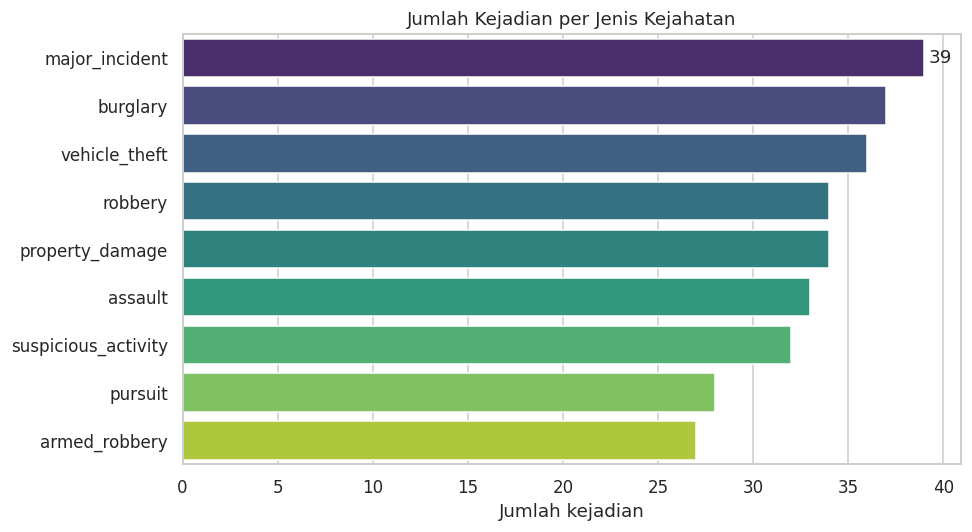

In [9]:
order = df_clean["crime_type"].value_counts().index
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df_clean, y="crime_type", order=order, palette="viridis")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Jumlah Kejadian per Jenis Kejahatan")
plt.xlabel("Jumlah kejadian"); plt.ylabel("")
plt.tight_layout(); plt.show()

**2) KEJADIAN PER WILAYAH (BOROUGH)**

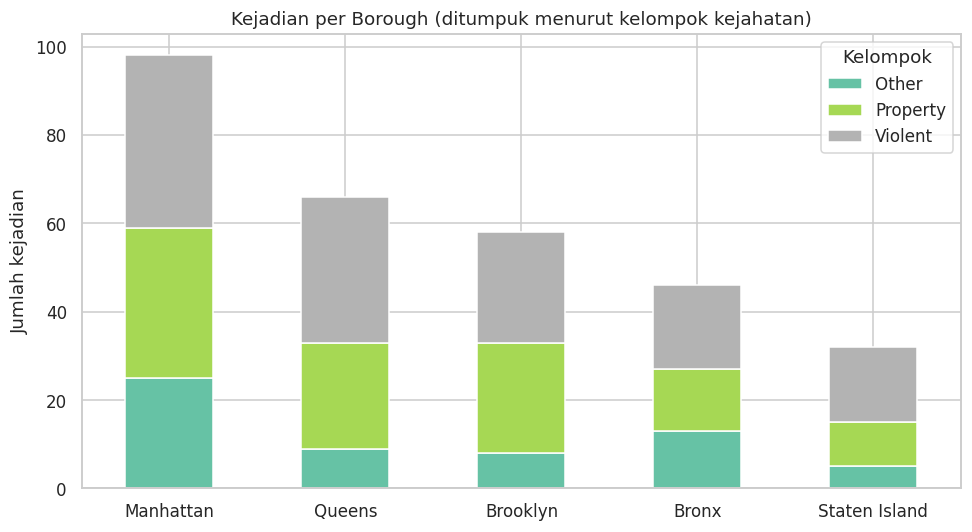

In [10]:
tab = pd.crosstab(df_clean["borough"], df_clean["crime_group"])
tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]
ax = tab.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="Set2")
plt.title("Kejadian per Borough (ditumpuk menurut kelompok kejahatan)")
plt.xlabel(""); plt.ylabel("Jumlah kejadian"); plt.xticks(rotation=0)
plt.legend(title="Kelompok"); plt.tight_layout(); plt.show()

**POLA KEJADIAN PER JAM**

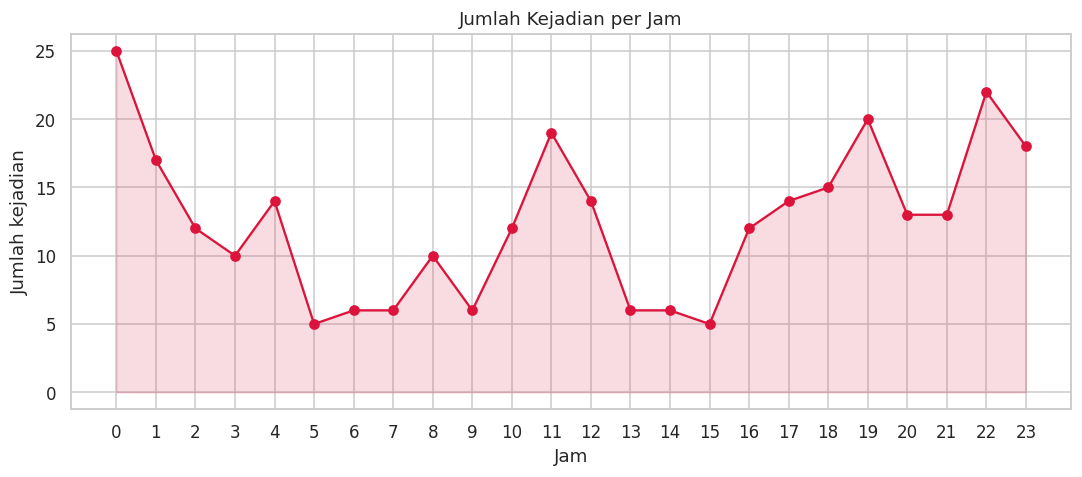

In [11]:
per_jam = df_clean["hour"].value_counts().reindex(range(24), fill_value=0).sort_index()
plt.figure(figsize=(10, 4.5))
plt.plot(per_jam.index, per_jam.values, marker="o", color="crimson")
plt.fill_between(per_jam.index, per_jam.values, alpha=0.15, color="crimson")
plt.xticks(range(24)); plt.xlabel("Jam"); plt.ylabel("Jumlah kejadian")
plt.title("Jumlah Kejadian per Jam"); plt.tight_layout(); plt.show()

**TREN KEJADIAN PER BULAN**

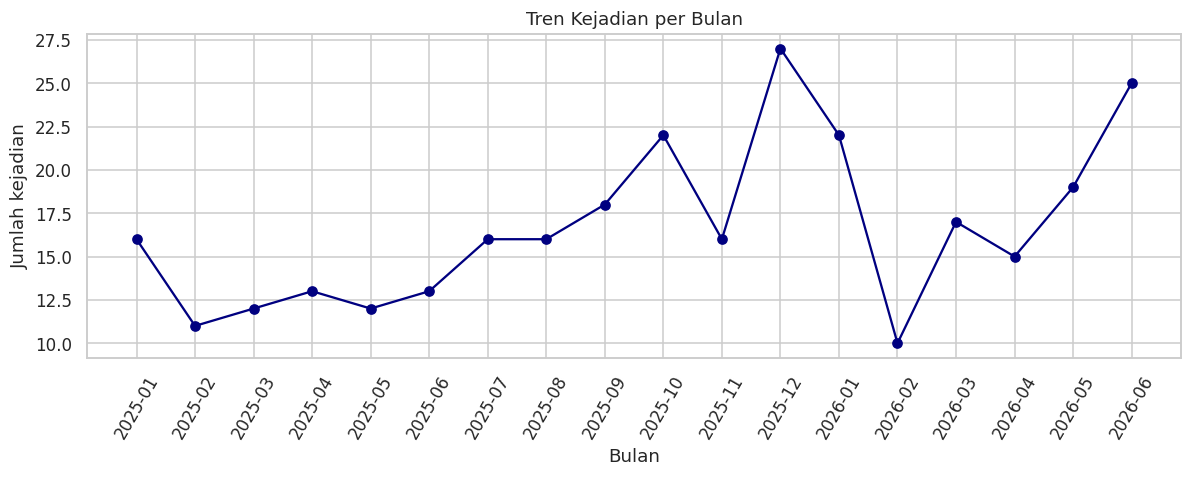

In [12]:
tren = df_clean.groupby("year_month").size()
plt.figure(figsize=(11, 4.5))
plt.plot(tren.index, tren.values, marker="o", color="navy")
plt.xticks(rotation=60); plt.xlabel("Bulan"); plt.ylabel("Jumlah kejadian")
plt.title("Tren Kejadian per Bulan"); plt.tight_layout(); plt.show()

**DISTRIBUSI SEVERITY SCORE**

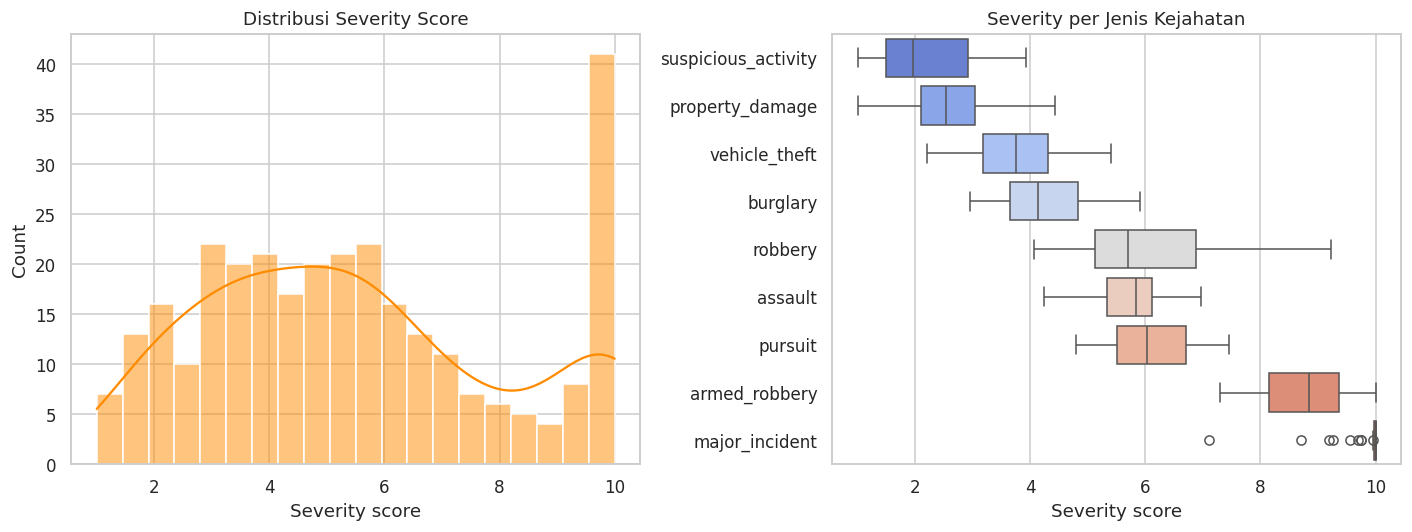

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df_clean["severity_score"], bins=20, kde=True, color="darkorange", ax=ax[0])
ax[0].set_title("Distribusi Severity Score"); ax[0].set_xlabel("Severity score")

urut = df_clean.groupby("crime_type")["severity_score"].median().sort_values().index
sns.boxplot(data=df_clean, y="crime_type", x="severity_score", order=urut, palette="coolwarm", ax=ax[1])
ax[1].set_title("Severity per Jenis Kejahatan"); ax[1].set_xlabel("Severity score"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**HEATMAP HARI DAN WAKTU**

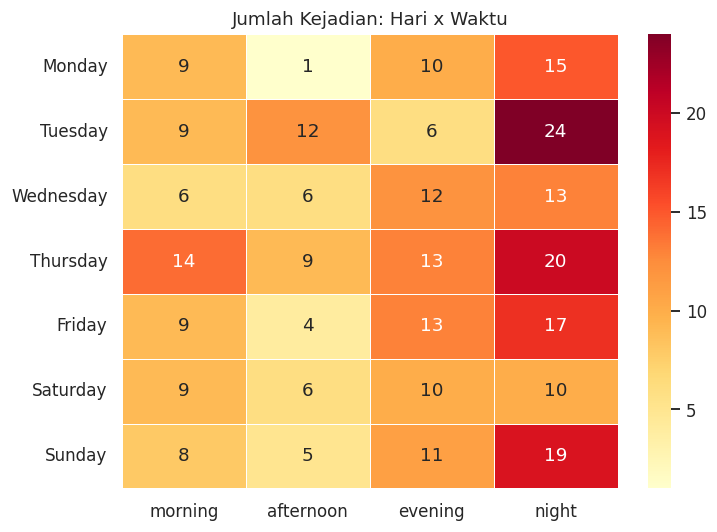

In [14]:
pivot = pd.crosstab(df_clean["day_name"], df_clean["time_of_day"])
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5)
plt.title("Jumlah Kejadian: Hari x Waktu"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**SEBARAN LOKASI KEJADIAN**

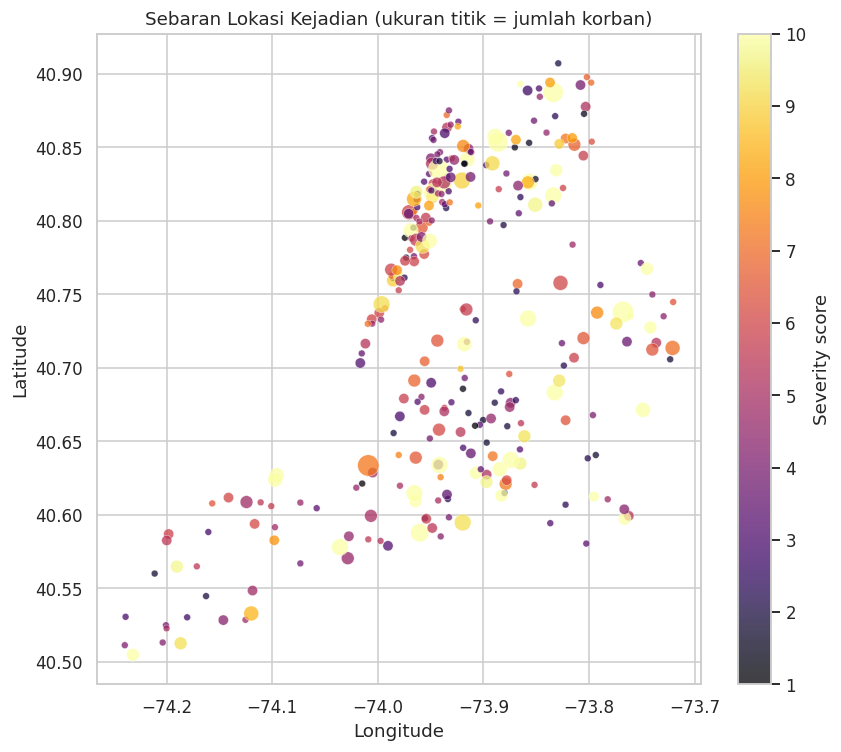

In [15]:
plt.figure(figsize=(8, 7))
sc = plt.scatter(df_clean["longitude"], df_clean["latitude"],
                 c=df_clean["severity_score"], s=20 + df_clean["victim_count"].astype(int) * 25,
                 cmap="inferno", alpha=0.75, edgecolor="white", linewidth=0.3)
plt.colorbar(sc, label="Severity score")
plt.title("Sebaran Lokasi Kejadian (ukuran titik = jumlah korban)")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.tight_layout(); plt.show()

**RESPON KEPOLISIAN**

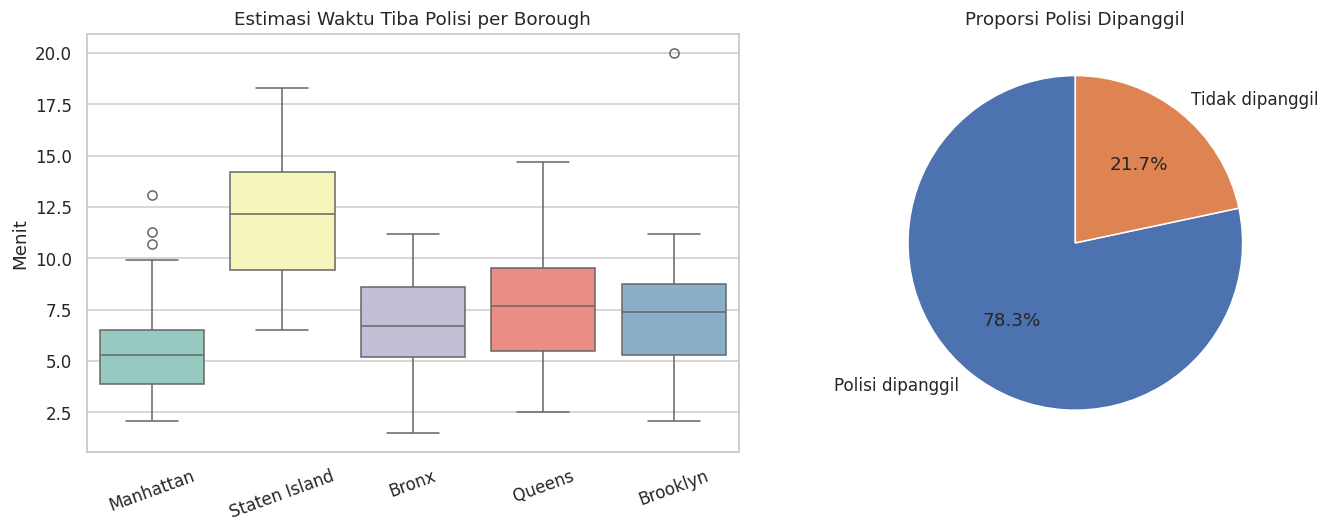

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_clean, x="borough", y="eta_if_called", palette="Set3", ax=ax[0])
ax[0].set_title("Estimasi Waktu Tiba Polisi per Borough"); ax[0].set_ylabel("Menit"); ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=20)

pc = df_clean["police_called"].map({True: "Polisi dipanggil", False: "Tidak dipanggil"}).value_counts()
ax[1].pie(pc, labels=pc.index, autopct="%1.1f%%", startangle=90, colors=["#4c72b0", "#dd8452"])
ax[1].set_title("Proporsi Polisi Dipanggil")
plt.tight_layout(); plt.show()

**KEJADIAN DENGAN SENJATA DAN KORBAN KEJAHATAN**

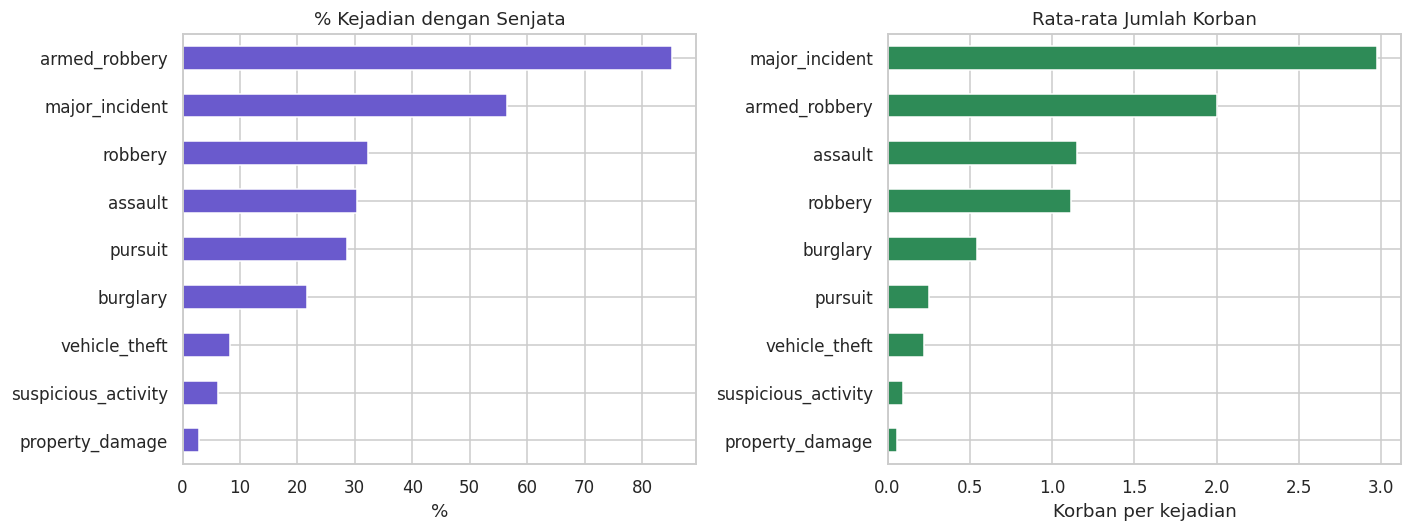

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
w = df_clean.groupby("crime_type")["weapon_reported"].mean().sort_values() * 100
w.plot(kind="barh", color="slateblue", ax=ax[0])
ax[0].set_title("% Kejadian dengan Senjata"); ax[0].set_xlabel("%"); ax[0].set_ylabel("")

v = df_clean.groupby("crime_type")["victim_count"].mean().sort_values()
v.plot(kind="barh", color="seagreen", ax=ax[1])
ax[1].set_title("Rata-rata Jumlah Korban"); ax[1].set_xlabel("Korban per kejadian"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**RINGKASAN HASIL ANALISIS**

In [18]:
total   = len(df_clean)
top_c   = df_clean["crime_type"].value_counts()
top_b   = df_clean["borough"].value_counts()
top_h   = df_clean["hour"].value_counts()
sev_c   = df_clean.groupby("crime_type")["severity_score"].mean().sort_values(ascending=False)
eta_b   = df_clean.groupby("borough")["eta_if_called"].mean().sort_values()

print("="*60); print("RINGKASAN ANALISIS"); print("="*60)
print(f"Periode data        : {df_clean['date'].min():%d %b %Y} - {df_clean['date'].max():%d %b %Y}")
print(f"Total kejadian      : {total}")
print(f"Jenis terbanyak     : {top_c.index[0]} ({top_c.iloc[0]} kejadian, {top_c.iloc[0]/total:.1%})")
print(f"Borough terbanyak   : {top_b.index[0]} ({top_b.iloc[0]/total:.1%})")
print(f"Jam paling rawan    : {top_h.index[0]}:00 ({top_h.iloc[0]} kejadian)")
print(f"Waktu paling rawan  : {df_clean['time_of_day'].value_counts().idxmax()}")
print(f"Rata-rata severity  : {df_clean['severity_score'].mean():.2f}")
print(f"Paling parah (rata2): {sev_c.index[0]} ({sev_c.iloc[0]:.2f})")
print(f"Kejadian Critical   : {(df_clean['severity_level']=='Critical').mean():.1%}")
print(f"Ada senjata         : {df_clean['weapon_reported'].mean():.1%}")
print(f"Ada korban          : {df_clean['has_victim'].mean():.1%}")
print(f"Polisi dipanggil    : {df_clean['police_called'].mean():.1%}")
print(f"ETA tercepat        : {eta_b.index[0]} ({eta_b.iloc[0]:.1f} mnt) | terlambat: {eta_b.index[-1]} ({eta_b.iloc[-1]:.1f} mnt)")
print(f"Kejadian decoy      : {df_clean['is_decoy_event'].sum()} ({df_clean['is_decoy_event'].mean():.1%})")
print(f"Korelasi severity-victim_count : {df_clean['severity_score'].corr(df_clean['victim_count'].astype(float)):.2f}")

RINGKASAN ANALISIS
Periode data        : 05 Jan 2025 - 30 Jun 2026
Total kejadian      : 300
Jenis terbanyak     : major_incident (39 kejadian, 13.0%)
Borough terbanyak   : Manhattan (32.7%)
Jam paling rawan    : 0:00 (25 kejadian)
Waktu paling rawan  : night
Rata-rata severity  : 5.46
Paling parah (rata2): major_incident (9.82)
Kejadian Critical   : 21.0%
Ada senjata         : 29.3%
Ada korban          : 47.7%
Polisi dipanggil    : 78.3%
ETA tercepat        : Manhattan (5.6 mnt) | terlambat: Staten Island (12.1 mnt)
Kejadian decoy      : 22 (7.3%)
Korelasi severity-victim_count : 0.71
